# Agentic AI for Science, Part 1a: Building a Scientific Agent

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nathanmaulding/tutorial-projects/blob/main/agentic-ai-for-science/01_building_a_science_agent.ipynb)

Scientists build **mechanistic models**: equations that say *how* a system works, such as how fast an enzyme turns substrate into product, or how a drug's concentration rises and falls in the body. A good mechanistic model predicts experiments that haven't been run yet. Finding one is iterative work: look at the data, recall candidate mechanisms, fit them, notice where they fail, revise.

In this notebook we build an **AI agent that does that work**, from scratch, and watch it reason through real problems.

**What you'll learn**

1. What an agent actually is: a model, tools, and a loop
2. **Tool use**: how a language model calls your Python functions
3. **Retrieval**: giving the agent a searchable library of domain knowledge
4. **Code execution**: letting the agent write and run code, safely
5. **Planning and hypothesis tracking**: making the agent's reasoning explicit and auditable
6. Reading a recorded agent run step by step, including one where the agent invents a mechanism that isn't in its library

**Runtime:** about a minute. **No API key needed**: by default the notebook replays recorded agent runs. Section 9 shows how to run the agent live with your own key.

> 🎬 *Video walkthrough: coming soon.* Part 1b (notebook 02) benchmarks the agent and asks how far to trust it.

## 0. Setup

On Colab this cell downloads the project. Locally, run the notebook from the `agentic-ai-for-science` folder.

In [1]:
import os, sys, json
if "google.colab" in sys.modules and not os.path.exists("agentlab"):
    !git clone -q --depth 1 https://github.com/nathanmaulding/tutorial-projects.git
    %cd tutorial-projects/agentic-ai-for-science
    !pip install -q -r requirements.txt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

plt.rcParams.update({"figure.figsize": (7, 4.2), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 11})
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]  # validated categorical order

## 1. What is an agent?

A language model on its own turns text into text. An **agent** is a language model in a loop with **tools**:

```
            ┌────────────────────────────────────────────┐
            │  conversation so far (task, past steps)    │
            └───────────────┬────────────────────────────┘
                            ▼
                     ┌─────────────┐   "call fit_model(...)"   ┌──────────────┐
                     │    model    │ ────────────────────────▶ │  your tools  │
                     └─────────────┘ ◀──────────────────────── │  (Python)    │
                            │          tool result appended    └──────────────┘
                            ▼
                 no more tool calls?  →  done
```

Each turn, the model reads the whole conversation and either answers or asks to call one or more tools. Our code runs the tools, appends the results to the conversation, and asks again. That's all an agent is. Everything that looks like intelligence (planning, looking things up, testing ideas) is behaviour the model chooses *inside* this loop, shaped by two things we control: **which tools exist** and **the instructions** (the system prompt).

This project's framework, `agentlab`, is about 650 lines you can read in one sitting:

| Module | Job |
|---|---|
| `agentlab/agent.py` | the loop above, plus guard rails (step limit, dollar caps, a full trace) |
| `agentlab/tools.py` | turns Python functions into tools the model can call |
| `agentlab/retrieval.py` | a tiny search engine over a folder of markdown documents |
| `agentlab/sandbox.py` | runs model-written code in a separate process with no secrets |
| `agentlab/models.py` | the only place that knows model names and prices; swap models with one setting |
| `agentlab/budget.py`, `trace.py` | a hard spending cap, and a replayable record of every step |

## 2. The scientific problem

Here's one of the 18 benchmark tasks. An enzyme's reaction rate `v` was measured at several substrate concentrations `S`, with three different amounts of an inhibitor `I`. The data were simulated from a known mechanism, which the agent never sees, plus measurement noise.

In [2]:
from mechanism_discovery.tasks import TASKS_BY_ID, make_instance

inst = make_instance(TASKS_BY_ID["enz_competitive"], seed=0)
print(inst.prompt())
inst.data.head()

Initial reaction rates v (uM/min) of a purified enzyme were measured at substrate concentrations S (uM) and inhibitor concentrations I (uM). Each condition was measured in duplicate; rates carry additive measurement noise.

The data table has 48 rows with columns: S, I, v. Your model will be used to predict rates at higher inhibitor concentrations.

Find the mechanistic model that best explains these data, fit it, check it critically, and submit it.


,S,I,v
0,0.25,0,1.2688
1,0.50,0,2.0023
2,1.00,0,3.4579
3,2.00,0,4.4775
4,4.00,0,6.6946


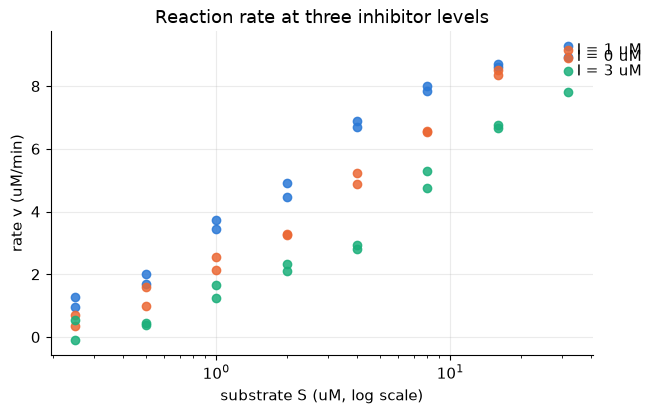

In [3]:
fig, ax = plt.subplots()
for color, (I, g) in zip(SERIES, inst.data.groupby("I")):
    ax.plot(g.S, g.v, "o", ms=6, color=color, alpha=0.85)
    last = g.sort_values("S").iloc[-1]
    ax.annotate(f"I = {I:g} uM", (last.S, last.v), xytext=(6, 0), textcoords="offset points", va="center")
ax.set(xscale="log", xlabel="substrate S (uM, log scale)", ylabel="rate v (uM/min)",
       title="Reaction rate at three inhibitor levels")
plt.show()

> ⏸️ **Pause and predict:** the inhibitor clearly slows the reaction. But look at the highest substrate level: does the inhibition get *overcome* there, or does it persist? Biochemists use exactly this clue to tell kinds of inhibition apart.

**How we'll judge the agent.** Two things are hidden from it:
- the **true mechanism**, and
- a set of **held-out conditions**: here, inhibitor levels of 6 and 10 uM, higher than anything measured.

The agent's final model must predict those held-out conditions. That's the honest test of a mechanistic model: extrapolating to experiments not yet run, not just fitting the data you have.

## 3. Tool use: how a model calls your code

A tool is a **name**, a **description** the model reads, a **JSON schema** for its inputs, and a **Python function**. Here are the tools for this task. The descriptions are the only documentation the model gets, so they matter as much as the code.

In [4]:
from mechanism_discovery.agent_tools import MechanismSession

session = MechanismSession(inst, arm="agent_full")
tools = session.registry()
for spec in tools.specs():
    print(f"{spec['name']:26s} {spec['description'][:95]}...")

write_plan                 Record your plan as a short list of steps. Call it first, and again whenever your plan changes....
inspect_data               Summary of the data table: columns, ranges, first rows and per-group statistics....
run_python                 Run Python for exploratory analysis. The data is preloaded as a pandas DataFrame `df`; numpy (n...
search_mechanism_library   Search the mechanism library (cards describing candidate mechanisms, how to recognise them, and...
read_mechanism_card        Read a mechanism card in full: equations, assumptions, data signatures, pitfalls, the library m...
fit_model                  Fit a model by nonlinear least squares (all parameters positive; fitted on a log scale, multi-s...
record_hypothesis          Add or update a hypothesis on your hypothesis board: the mechanism, what it predicts in these d...
submit_model               Submit your final model. Ends the task. fit_id must be one of your fits. Use mechanism_label 'c...


In [5]:
print(json.dumps(tools.specs()[5], indent=1)[:1100])   # the full spec for fit_model, exactly as the model sees it

{
 "name": "fit_model",
 "description": "Fit a model by nonlinear least squares (all parameters positive; fitted on a log scale, multi-start). Returns parameters, relative standard errors, AIC, BIC, identifiability warnings and residual diagnostics, plus a fit_id. error_model: 'additive' (constant noise) or 'proportional' (noise scales with the value; fits log residuals). For model='custom', custom_code must define PARAMS = ['name', ...] and def predict(df, p): returning a numpy array with one prediction per row of df (p is a dict of parameter values). np, pd, scipy, solve_ivp, pk_conc(dose, t) and per_dose(df, solve_one) are available; per_dose calls solve_one(dose, sorted_times) for each dose group and maps results back to rows. Or set model to a library model name found in the mechanism cards.",
 "input_schema": {
  "type": "object",
  "properties": {
   "model": {
    "type": "string",
    "description": "library model name, or 'custom'"
   },
   "error_model": {
    "type": "strin

When the model wants to use a tool it doesn't run anything itself. It replies with a structured request, for example:

```json
{"type": "tool_use", "name": "fit_model",
 "input": {"model": "competitive_inhibition", "error_model": "additive",
           "initial_params": {"Vmax": 10, "Km": 3, "Ki": 2}}}
```

Our loop runs the function and sends the result back. Let's play the agent ourselves and make the same calls by hand: fit two competing inhibition mechanisms and compare them.

In [6]:
competitive = session.fit_model("competitive_inhibition", "additive", {"Vmax": 10, "Km": 3, "Ki": 2})
noncompetitive = session.fit_model("noncompetitive_inhibition", "additive", {"Vmax": 10, "Km": 3, "Ki": 2})
for f in (competitive, noncompetitive):
    print(f"{f['fit_id']}  {f['model']:27s} BIC = {f['bic']:7.1f}   params = {f['params']}")
    print("      residuals:", f["residual_diagnostics"]["notes"])

fit1  competitive_inhibition      BIC =  -111.4   params = {'Vmax': 9.946, 'Km': 1.996, 'Ki': 1.05}
      residuals: ['No systematic structure detected in the residuals.']
fit2  noncompetitive_inhibition   BIC =   -35.2   params = {'Vmax': 11.02, 'Km': 3.336, 'Ki': 6.988}
      residuals: ['Residuals trend with I (Spearman rho=-0.37): the model misses how I affects v.', 'Residual signs are clustered (runs test z=-4.1): systematic misfit, not noise.']


**What just happened:** each fit returns more than parameter values. It returns evidence a scientist would want: **BIC** (fit quality penalised for the number of parameters; lower is better, and a gap above about 6 is strong evidence), the parameters' **relative standard errors**, **identifiability warnings**, and **residual diagnostics** in plain language. The competitive model wins decisively, and its residuals show no structure. Designing tool outputs like this, as evidence rather than raw numbers, is most of the work of building a good scientific agent.

## 4. Retrieval: a library the agent can search

The agent shouldn't have to remember every rate law. It gets a **mechanism library**: 16 short markdown "cards", each with a mechanism's equations, the data signatures that identify it, pitfalls, the name of the library model to fit, and a textbook or paper reference. There are also method cards on model selection, residual diagnostics and identifiability.

Retrieval here is **BM25**, a classic keyword-ranking formula: documents score higher when they contain the query's rarer words. No embeddings or external service, and you can see exactly why each card was returned.

In [7]:
for q in ["inhibitor raises apparent Km but Vmax unchanged",
          "concentration falls more slowly at higher dose",
          "effect lags behind plasma concentration"]:
    hits = session.search_mechanism_library(q)
    print(f"{q!r}\n   -> " + ", ".join(f"{h['card_id']} ({h['score']})" for h in hits[:3]))

'inhibitor raises apparent Km but Vmax unchanged'
   -> reversible_inhibition (13.04), michaelis_menten (3.91), first_order_regime (3.77)
'concentration falls more slowly at higher dose'
   -> pk_saturable_elimination (9.86), pd_indirect_response (6.49), substrate_inhibition (3.97)
'effect lags behind plasma concentration'
   -> pd_emax (9.08), pd_effect_compartment (5.77), null_model (2.43)


In [8]:
print(session.read_mechanism_card("reversible_inhibition")[:1400])

# Reversible inhibition: competitive, uncompetitive and noncompetitive (mixed with alpha = 1)
library_model: competitive_inhibition, uncompetitive_inhibition, noncompetitive_inhibition

Equations (I = inhibitor concentration, Ki = inhibition constant):
- Competitive (inhibitor binds free enzyme only):  v = Vmax*S / (Km*(1 + I/Ki) + S)
- Uncompetitive (binds ES complex only):            v = Vmax*S / (Km + S*(1 + I/Ki))
- Noncompetitive (binds E and ES equally):          v = Vmax*S / ((Km + S)*(1 + I/Ki))

Data signatures (compare curves at different I):
- Competitive: apparent Km increases with I, Vmax unchanged; inhibition is overcome at high S. Lineweaver-Burk lines intersect on the y-axis.
- Uncompetitive: apparent Vmax and apparent Km both decrease by the same factor; parallel Lineweaver-Burk lines.
- Noncompetitive: apparent Vmax decreases, Km unchanged; lines intersect on the x-axis.

All three models are "complete" inhibition: as I goes to infinity the rate goes to zero. If activ

Notice the card's last line before the citation: *all three models are complete inhibition; if activity levels off at a nonzero fraction, none of these apply.* Good retrieval doesn't just hand over equations. It tells the agent when the library **runs out**, which matters for the hardest tasks.

## 5. Code execution, safely

The agent can write Python, both for quick analyses (`run_python`) and for **new models of its own** (`fit_model` with `model="custom"`). Model-written code runs in a separate process (`agentlab/sandbox.py`):

- the child process gets a **minimal environment with no API keys**, so model-written code can't read or print your key, and a key can never end up in a saved trace;
- a timeout kills runaway code, and a crash only kills the child.

Let's prove the first point with a fake key:

In [9]:
from agentlab.sandbox import run_python

os.environ["DEMO_SECRET_API_KEY"] = "not-a-real-key"
print(run_python("import os; print('child sees:', os.environ.get('DEMO_SECRET_API_KEY'))").stdout)
del os.environ["DEMO_SECRET_API_KEY"]

child sees: None



In [10]:
custom = '''
PARAMS = ["Vmax", "Km", "Ki"]
def predict(df, p):          # competitive inhibition, written by hand
    S, I = df["S"].values, df["I"].values
    return p["Vmax"] * S / (p["Km"] * (1 + I / p["Ki"]) + S)
'''
f = session.fit_model("custom", "additive", {"Vmax": 10, "Km": 3, "Ki": 2}, custom_code=custom)
print(f["fit_id"], f["params"], "BIC", f["bic"])

fit3 {'Vmax': 9.946, 'Km': 1.996, 'Ki': 1.05} BIC -111.39


**What just happened:** the hand-written model ran in the sandbox and gave the same answer as the library version. This is the escape hatch that lets the agent go beyond its library.

*(The sandbox is "isolation-lite": it doesn't block network or filesystem access. That's fine for a tutorial running a model you chose on tasks you wrote. For untrusted use, run the child process in a container.)*

## 6. The loop itself

Here is the heart of `agentlab/agent.py`, lightly trimmed:

```python
messages = [{"role": "user", "content": task_prompt}]
for step in range(1, cfg.max_steps + 1):
    ledger.check(...)                                   # refuse to send if it could break the dollar cap
    resp = client.create(system=system, messages=messages, tools=tool_specs, max_tokens=...)
    messages.append({"role": "assistant", "content": resp.content})   # append exactly as received

    calls = resp.tool_calls
    if not calls:                                       # the model answered instead of calling tools
        if is_done(): return finish("done")
        messages.append({"role": "user", "content": "You haven't submitted. Finish now."})  # one reminder
        continue

    results = []
    for call in calls:                                  # the model may ask for several tools at once
        out, is_error, _ = tools.execute(call["name"], call["input"])   # errors go back to the model
        results.append({"type": "tool_result", "tool_use_id": call["id"], "content": out, "is_error": is_error})
    messages.append({"role": "user", "content": results})               # all results in one message
    if is_done(): return finish("done")
```

Three design choices worth knowing:
- **Errors are results, not crashes.** If the model passes bad arguments, it gets the error message back and can fix its call.
- **Parallel tool calls.** The model can fit four candidate models in one turn, and all four results go back together.
- **The conversation is the memory.** Nothing is hidden: every step is appended, and every step is written to a trace file you can replay.

## 7. Planning and hypotheses, made explicit

Two tools don't compute anything. They make the agent's thinking **visible and auditable**:

- `write_plan` records a short plan up front and whenever it changes.
- `record_hypothesis` keeps a board of competing hypotheses, each with its prediction, status (proposed / supported / rejected / inconclusive) and the fits that are its evidence.

The system prompt asks for at least two competing hypotheses, which pushes the agent to *compare* mechanisms rather than confirm its first guess. It also asks the agent to always consider the simplest model, including "no effect at all", and to cite a fit for every number it reports.

In [11]:
from mechanism_discovery import prompts
print(prompts.AGENT_FULL.format(max_steps=20))

You are a computational scientist who builds mechanistic models of biochemical and pharmacological processes from experimental data. Work the way a careful scientist does:

1. Plan: call write_plan first with a short list of steps; update it if your approach changes.
2. Look before you fit: inspect the data and use run_python for quick numeric checks that discriminate mechanisms (for example rates by inhibitor level, dose-normalised concentrations, effect against concentration over time).
3. Retrieve: search the mechanism library and read the relevant cards. They give equations, data signatures, pitfalls and the library model name to fit.
4. Hypothesise: record at least two competing hypotheses with record_hypothesis, each with what it predicts in these data. Update their status as evidence comes in.
5. Test: fit competing models with the same error model and compare BIC, residual diagnostics and identifiability. Fit independent models in the same turn to save steps.
6. Revise: if ever

## 8. Watch the agent work (recorded runs)

These are real runs of the agent on the benchmark, recorded once and replayed here for free. Each step shows the model's reasoning summary, what it said, the tools it called, and the results (click to expand).

### 8a. A standard task: the inhibitor data above

In [12]:
from pathlib import Path
from agentlab.replay import show

def pick_trace(task_id, arm="agent_full", prefer=("claude-haiku-5-5", "claude-opus-5-5"), success=True):
    rows = [json.loads(l) for l in open("runs/part1/results.jsonl")]
    for model in prefer:
        for r in rows:
            if (r["task_id"] == task_id and r["arm"] == arm and r["model"] == model
                    and r["success"] == success and r.get("trace") and Path(r["trace"]).exists()):
                return r["trace"]
    return None

show(pick_trace("enz_competitive"))

**Run** `enz_competitive__s0__agent_full__claude-haiku-5-5__r1`  
**Model:** `claude-haiku-5-5`  
**Tools available:** write_plan, inspect_data, run_python, search_mechanism_library, read_mechanism_card, fit_model, record_hypothesis, submit_model

**Task given to the agent:**

> Initial reaction rates v (uM/min) of a purified enzyme were measured at substrate concentrations S (uM) and inhibitor concentrations I (uM). Each condition was measured in duplicate; rates carry additive measurement noise.
> 
> The data table has 48 rows with columns: S, I, v. Your model will be used to predict rates at higher inhibitor concentrations.
> 
> Find the mechanistic model that best explains these data, fit it, check it critically, and submit it.

---
### Step 1  
<sub>2,613 input tokens (0 from cache), 164 output, $0.0004</sub>

**Calls `write_plan`** `{"steps": ["Inspect data and compute per-inhibitor Michaelis-Menten summaries", "Search mechanism library for inhibition models", "Fit competitive, noncompetitive, uncompetitive, MM baseline; compare BIC", "Check residuals, submit best model"]}`

**Calls `inspect_data`** `{}`

<details><summary>Result of <code>write_plan</code></summary>

```
Plan recorded:
1. Inspect data and compute per-inhibitor Michaelis-Menten summaries
2. Search mechanism library for inhibition models
3. Fit competitive, noncompetitive, uncompetitive, MM baseline; compare BIC
4. Check residuals, submit best model
```
</details>

<details><summary>Result of <code>inspect_data</code></summary>

```
{
 "rows": 48,
 "columns": [
  "S",
  "I",
  "v"
 ],
 "describe": {
  "S": {
   "count": 48.0,
   "mean": 7.9688,
   "std": 10.4615,
   "min": 0.25,
   "25%": 0.875,
   "50%": 3.0,
   "75%": 10.0,
   "max": 32.0
  },
  "I": {
   "count": 48.0,
   "mean": 1.3333,
   "std": 1.2604,
   "min": 0.0,
   "25%": 0.0,
   "50%": 1.0,
   "75%": 3.0,
   "max": 3.0
  },
  "v": {
   "count": 48.0,
   "mean": 4.47,
   "std": 3.0518,
   "min": -0.0977,
   "25%": 1.6704,
   "50%": 4.1062,
   "75%": 7.126,
   "max": 9.2756
  }
 },
 "first_rows": [
  {
   "S": 0.25,
   "I": 0,
   "v": 1.2688
  },
  {
   "S": 0.5,
   "I": 0,
   "v": 2.0023
  },
  {
   "S": 1.0,
   "I": 0,
   "v": 3.4579
  }, ... [513 more chars]
```
</details>

---
### Step 2  
<sub>3,716 input tokens (2,609 from cache), 180 output, $0.0003</sub>

**Calls `search_mechanism_library`** `{"query": "enzyme inhibition competitive noncompetitive uncompetitive Michaelis-Menten"}`

**Calls `run_python`** `{}`

```python
for I in [0,1,3]:
    d=df[df.I==I].sort_values('S')
    print(I); print(d[['S','v']].to_string(index=False))
```

<details><summary>Result of <code>search_mechanism_library</code></summary>

```
[
 {
  "card_id": "reversible_inhibition",
  "title": "Reversible inhibition: competitive, uncompetitive and noncompetitive (mixed with alpha = 1)",
  "library_model": "competitive_inhibition, uncompetitive_inhibition, noncompetitive_inhibition",
  "score": 15.96
 },
 {
  "card_id": "michaelis_menten",
  "title": "Michaelis-Menten kinetics (single substrate, hyperbolic)",
  "library_model": "mm",
  "score": 5.95
 },
 {
  "card_id": "substrate_inhibition",
  "title": "Substrate inhibition (rate falls at high substrate)",
  "library_model": "substrate_inhibition",
  "score": 5.46
 },
 {
  "card_id": "first_order_regime",
  "title": "First-order (linear) regime of enzyme kin ... [83 more chars]
```
</details>

<details><summary>Result of <code>run_python</code></summary>

```
0
    S      v
 0.25 1.2688
 0.25 0.9662
 0.50 1.6787
 0.50 2.0023
 1.00 3.4579
 1.00 3.7350
 2.00 4.9236
 2.00 4.4775
 4.00 6.8938
 4.00 6.6946
 8.00 7.9922
 8.00 7.8568
16.00 8.7039
16.00 8.5999
32.00 9.2756
32.00 8.9311
1
    S      v
 0.25 0.6881
 0.25 0.3612
 0.50 0.9947
 0.50 1.5858
 1.00 2.1437
 1.00 2.5621
 2.00 3.2970
 2.00 3.2516
 4.00 4.8904
 4.00 5.2192
 8.00 6.5358
 8.00 6.5720
16.00 8.5141
16.00 8.3442
32.00 8.9096
32.00 9.1396
3
    S       v
 0.25  0.5390
 0.25 -0.0977
 0.50  0.3766
 0.50  0.4381
 1.00  1.2509
 1.00  1.6454
 2.00  2.3148
 2.00  2.1142
 4.00  2.9274
 4.00  2.8174
 8.00  4.7450
 8.00  5.2858
16.00  6.7674
16.00  6.6784
32.00  7.8224
32.00  8.4672
```
</details>

---
### Step 3  
<sub>4,793 input tokens (3,714 from cache), 613 output, $0.0005</sub>

*Reasoning (summary):* Vmax looks like it stays near 9.5 across all inhibitor concentrations, while the apparent Km rises with I, which points to competitive-style inhibition. I'll fit competitive, uncompetitive, noncompetitive, and Michaelis-Menten models to compare them.  

**Says:** The Vmax looks roughly unchanged while the apparent Km rises with I, which points to competitive inhibition. I'll fit the candidate models and the no-inhibitor baseline together.

**Calls `fit_model`** `{"model": "competitive_inhibition", "error_model": "additive", "initial_params": {"Vmax": 10, "Km": 3, "Ki": 2}}`

**Calls `fit_model`** `{"model": "noncompetitive_inhibition", "error_model": "additive", "initial_params": {"Vmax": 10, "Km": 3, "Ki": 2}}`

**Calls `fit_model`** `{"model": "uncompetitive_inhibition", "error_model": "additive", "initial_params": {"Vmax": 10, "Km": 3, "Ki": 2}}`

**Calls `fit_model`** `{"model": "mm", "error_model": "additive", "initial_params": {"Vmax": 10, "Km": 3}}`

<details><summary>Result of <code>fit_model</code></summary>

```
{
 "fit_id": "fit1",
 "model": "competitive_inhibition",
 "params": {
  "Vmax": 9.946,
  "Km": 1.996,
  "Ki": 1.05
 },
 "relative_se": {
  "Vmax": "1%",
  "Km": "6%",
  "Ki": "8%"
 },
 "n": 48,
 "k": 3,
 "sigma": 0.2868,
 "aic": -117.0,
 "bic": -111.39,
 "error_model": "additive",
 "identifiability_warnings": [],
 "residual_diagnostics": {
  "residual_vs": {
   "S": -0.003,
   "I": 0.037
  },
  "notes": [
   "No systematic structure detected in the residuals."
  ],
  "runs_test_z": 0.0,
  "mean_residual_by_I_in_sigmas": {
   "0": -0.2,
   "1": 0.34,
   "3": -0.12
  }
 }
}
```
</details>

<details><summary>Result of <code>fit_model</code></summary>

```
{
 "fit_id": "fit2",
 "model": "noncompetitive_inhibition",
 "params": {
  "Vmax": 11.02,
  "Km": 3.336,
  "Ki": 6.988
 },
 "relative_se": {
  "Vmax": "3%",
  "Km": "10%",
  "Ki": "15%"
 },
 "n": 48,
 "k": 3,
 "sigma": 0.6341,
 "aic": -40.83,
 "bic": -35.22,
 "error_model": "additive",
 "identifiability_warnings": [],
 "residual_diagnostics": {
  "residual_vs": {
   "S": 0.041,
   "I": -0.37
  },
  "notes": [
   "Residuals trend with I (Spearman rho=-0.37): the model misses how I affects v.",
   "Residual signs are clustered (runs test z=-4.1): systematic misfit, not noise."
  ],
  "runs_test_z": -4.09,
  "mean_residual_by_I_in_sigmas": {
   "0": 0.39,
   "1": -0.01,
   "3": -0.43
  }
 }
}
```
</details>

<details><summary>Result of <code>fit_model</code></summary>

```
{
 "fit_id": "fit3",
 "model": "uncompetitive_inhibition",
 "params": {
  "Vmax": 11.07,
  "Km": 3.797,
  "Ki": 6.499
 },
 "relative_se": {
  "Vmax": "5%",
  "Km": "12%",
  "Ki": "22%"
 },
 "n": 48,
 "k": 3,
 "sigma": 0.7778,
 "aic": -21.22,
 "bic": -15.61,
 "error_model": "additive",
 "identifiability_warnings": [],
 "residual_diagnostics": {
  "residual_vs": {
   "S": 0.06,
   "I": -0.536
  },
  "notes": [
   "Residuals trend with I (Spearman rho=-0.54): the model misses how I affects v.",
   "Residual signs are clustered (runs test z=-4.1): systematic misfit, not noise."
  ],
  "runs_test_z": -4.08,
  "mean_residual_by_I_in_sigmas": {
   "0": 0.58,
   "1": -0.01,
   "3": -0.66
  }
 }
}
```
</details>

<details><summary>Result of <code>fit_model</code></summary>

```
{
 "fit_id": "fit4",
 "model": "mm",
 "params": {
  "Vmax": 9.663,
  "Km": 3.628
 },
 "relative_se": {
  "Vmax": "5%",
  "Km": "15%"
 },
 "n": 48,
 "k": 2,
 "sigma": 0.9992,
 "aic": 1.88,
 "bic": 5.62,
 "error_model": "additive",
 "identifiability_warnings": [],
 "residual_diagnostics": {
  "residual_vs": {
   "S": -0.001,
   "I": -0.908
  },
  "notes": [
   "Residuals trend with I (Spearman rho=-0.91): the model misses how I affects v.",
   "Residual signs are clustered (runs test z=-4.4): systematic misfit, not noise.",
   "Group I=3 is fit poorly on average (1.1 sigma)."
  ],
  "runs_test_z": -4.37,
  "mean_residual_by_I_in_sigmas": {
   "0": 1.02,
   "1": 0.11,
   "3": -1.07
  }
 }
}
```
</details>

---
### Step 4  
<sub>7,037 input tokens (4,791 from cache), 899 output, $0.0008</sub>

*Reasoning (summary):* Competitive inhibition still looks clearly better than the alternatives, with a much lower BIC. The residual pattern at I=1 is only slightly off, at about 0.34 sigma. I'm considering a mixed model with an extra alpha parameter, though competitive is the special case where alpha is infinite, so I'll run one quick custom fit of the mixed model and note the hypotheses.  

**Says:** Competitive inhibition fits far better than the others (BIC −111 vs −35 or worse). I'll check whether a mixed model (with an extra parameter for the inhibitor's effect on Vmax) improves on it.

**Calls `fit_model`** `{"model": "custom", "error_model": "additive", "initial_params": {"Vmax": 10, "Km": 2, "Ki": 1, "alpha": 1}}`

```python
PARAMS = ['Vmax','Km','Ki','alpha']
def predict(df, p):
    S = df['S'].values; I = df['I'].values
    return p['Vmax']*S/(p['Km']*(1+I/p['Ki']) + S*(1+I/(p['alpha']*p['Ki'])))
```

**Calls `record_hypothesis`** `{"hypothesis_id": "H1", "mechanism": "Competitive inhibition: inhibitor binds free enzyme only; Vmax unchanged, apparent Km rises with I", "status": "supported", "evidence": "fit1: Vmax 9.95, Km 2.00, Ki 1.05, BIC -111.4, no residual structure. Vmax ~constant across I in raw data."}`

**Calls `record_hypothesis`** `{"hypothesis_id": "H2", "mechanism": "Noncompetitive / uncompetitive / plain MM (no inhibition)", "status": "rejected", "evidence": "fit2 BIC -35, fit3 BIC -16, fit4 (no inhibitor term) BIC 6; all leave systematic residuals vs I (runs z about -4)."}`

<details><summary>Result of <code>fit_model</code></summary>

```
{
 "fit_id": "fit5",
 "model": "custom",
 "params": {
  "Vmax": 9.946,
  "Km": 1.996,
  "Ki": 1.05,
  "alpha": 502900000000000.0
 },
 "relative_se": {
  "Vmax": "1%",
  "Km": "6%",
  "Ki": "8%",
  "alpha": "0%"
 },
 "n": 48,
 "k": 4,
 "sigma": 0.29,
 "aic": -115.0,
 "bic": -107.52,
 "error_model": "additive",
 "identifiability_warnings": [],
 "residual_diagnostics": {
  "residual_vs": {
   "S": -0.003,
   "I": 0.037
  },
  "notes": [
   "No systematic structure detected in the residuals."
  ],
  "runs_test_z": 0.0,
  "mean_residual_by_I_in_sigmas": {
   "0": -0.2,
   "1": 0.34,
   "3": -0.11
  }
 }
}
```
</details>

<details><summary>Result of <code>record_hypothesis</code></summary>

```
Hypothesis board:
- H1: [supported] Competitive inhibition: inhibitor binds free enzyme only; Vmax unchanged, apparent Km rises with I
```
</details>

<details><summary>Result of <code>record_hypothesis</code></summary>

```
Hypothesis board:
- H1: [supported] Competitive inhibition: inhibitor binds free enzyme only; Vmax unchanged, apparent Km rises with I
- H2: [rejected] Noncompetitive / uncompetitive / plain MM (no inhibition)
```
</details>

---
### Step 5  
<sub>8,538 input tokens (7,035 from cache), 474 output, $0.0005</sub>

*Reasoning (summary):* The mixed model's alpha is heading toward infinity, which makes it purely competitive, so I'll submit fit1.  

**Calls `submit_model`** `{"fit_id": "fit1", "mechanism_label": "competitive_inhibition", "summary": "Rates follow Michaelis-Menten kinetics with the inhibitor raising the apparent Km while Vmax stays near 9.95 uM/min (fit1: Vmax 9.946, Km 1.996, Ki 1.05, BIC -111.4, no residual structure). Noncompetitive, uncompetitive and no-inhibitor MM fits all leave strong systematic residuals versus I (fit2, fit3, ... [335 more chars]`

<details><summary>Result of <code>submit_model</code></summary>

```
Submission recorded.
```
</details>

---
**Run ended:** done after 5 steps, 12 tool calls, $0.0024

**Scored against the hidden truth:** submitted `competitive_inhibition`; mechanism correct: True; held-out error 0.025 (threshold 0.05); **success: True**


### 8b. A hard task: a mechanism that isn't in the library

In this task the inhibitor's effect **levels off**: even a saturating dose leaves 40% of the enzyme's activity. No library model can do that, since they all drive activity to zero, so a search over the library fails (we'll measure that in notebook 02). To succeed, the agent has to notice the misfit, work out what the data are doing, and **write a new model**.

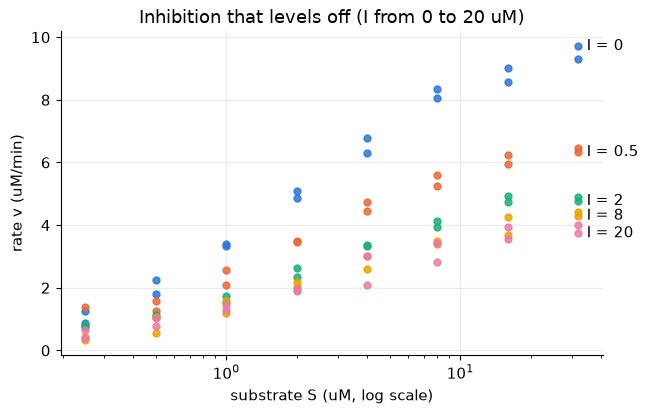

In [13]:
novel = make_instance(TASKS_BY_ID["hard_novel_partial_inhibition"], seed=0)
fig, ax = plt.subplots()
for color, (I, g) in zip(SERIES, novel.data.groupby("I")):
    ax.plot(g.S, g.v, "o", ms=5, color=color, alpha=0.85)
    last = g.sort_values("S").iloc[-1]
    ax.annotate(f"I = {I:g}", (last.S, last.v), xytext=(6, 0), textcoords="offset points", va="center")
ax.set(xscale="log", xlabel="substrate S (uM, log scale)", ylabel="rate v (uM/min)",
       title="Inhibition that levels off (I from 0 to 20 uM)")
plt.show()

In [14]:
path = pick_trace("hard_novel_partial_inhibition", prefer=("claude-opus-5-5", "claude-haiku-5-5"))
show(path) if path else print("No successful recorded run of this task yet.")

**Run** `hard_novel_partial_inhibition__s0__agent_full__claude-opus-5-5__r1`  
**Model:** `claude-opus-5-5`  
**Tools available:** write_plan, inspect_data, run_python, search_mechanism_library, read_mechanism_card, fit_model, record_hypothesis, submit_model

**Task given to the agent:**

> Initial reaction rates v (uM/min) of a purified enzyme were measured at substrate concentrations S (uM) and inhibitor concentrations I (uM). Each condition was measured in duplicate; rates carry additive measurement noise.
> 
> The data table has 80 rows with columns: S, I, v. Your model will be used to predict rates at much higher inhibitor concentrations.
> 
> Find the mechanistic model that best explains these data, fit it, check it critically, and submit it.

---
### Step 1  
<sub>2,614 input tokens (0 from cache), 125 output, $0.0156</sub>

**Calls `write_plan`** `{"steps": ["Inspect data", "Compare inhibition models (competitive, noncompetitive, uncompetitive, mixed/custom)", "Check residuals, submit"]}`

**Calls `inspect_data`** `{}`

<details><summary>Result of <code>write_plan</code></summary>

```
Plan recorded:
1. Inspect data
2. Compare inhibition models (competitive, noncompetitive, uncompetitive, mixed/custom)
3. Check residuals, submit
```
</details>

<details><summary>Result of <code>inspect_data</code></summary>

```
{
 "rows": 80,
 "columns": [
  "S",
  "I",
  "v"
 ],
 "describe": {
  "S": {
   "count": 80.0,
   "mean": 7.9688,
   "std": 10.4173,
   "min": 0.25,
   "25%": 0.875,
   "50%": 3.0,
   "75%": 10.0,
   "max": 32.0
  },
  "I": {
   "count": 80.0,
   "mean": 6.1,
   "std": 7.5601,
   "min": 0.0,
   "25%": 0.5,
   "50%": 2.0,
   "75%": 8.0,
   "max": 20.0
  },
  "v": {
   "count": 80.0,
   "mean": 3.3896,
   "std": 2.2966,
   "min": 0.33,
   "25%": 1.5084,
   "50%": 3.3386,
   "75%": 4.7355,
   "max": 9.7144
  }
 },
 "first_rows": [
  {
   "S": 0.25,
   "I": 0.0,
   "v": 1.2475
  },
  {
   "S": 0.5,
   "I": 0.0,
   "v": 1.7869
  },
  {
   "S": 1.0,
   "I": 0.0,
   "v": 3.4109
 ... [700 more chars]
```
</details>

---
### Step 2  
<sub>3,764 input tokens (2,610 from cache), 127 output, $0.0088</sub>

*Reasoning (summary):* I'm wondering if this is saturating inhibition, since the values level off at high inhibitor concentrations: 2.88, 2.41, 2.25. That plateau would point to only partial inhibition, so I want to look more closely.  

**Calls `run_python`** `{}`

```python
print(df.groupby(['I','S']).v.mean().unstack(0).round(2))
```

<details><summary>Result of <code>run_python</code></summary>

```
I      0.0   0.5   2.0   8.0   20.0
S                                  
0.25   1.07  1.08  0.78  0.38  0.53
0.50   2.02  1.41  1.09  0.81  0.91
1.00   3.38  2.32  1.64  1.39  1.37
2.00   4.97  3.47  2.50  2.10  1.93
4.00   6.55  4.59  3.34  2.81  2.55
8.00   8.20  5.41  4.04  3.45  3.13
16.00  8.80  6.09  4.82  3.97  3.74
32.00  9.50  6.39  4.83  4.37  3.87
```
</details>

---
### Step 3  
<sub>4,114 input tokens (3,762 from cache), 133 output, $0.0052</sub>

*Reasoning (summary):* The Vmax seems to fall to about 4 and level off, while Km looks roughly unchanged. That pattern suggests partial, hyperbolic noncompetitive inhibition, so I'm going to look for the relevant cards.  

**Calls `search_mechanism_library`** `{"query": "partial inhibition hyperbolic mixed saturating inhibitor"}`

<details><summary>Result of <code>search_mechanism_library</code></summary>

```
[
 {
  "card_id": "reversible_inhibition",
  "title": "Reversible inhibition: competitive, uncompetitive and noncompetitive (mixed with alpha = 1)",
  "library_model": "competitive_inhibition, uncompetitive_inhibition, noncompetitive_inhibition",
  "score": 9.74
 },
 {
  "card_id": "michaelis_menten",
  "title": "Michaelis-Menten kinetics (single substrate, hyperbolic)",
  "library_model": "mm",
  "score": 4.36
 },
 {
  "card_id": "method_residual_diagnostics",
  "title": "Method: reading residuals to find a missing mechanism",
  "library_model": "none",
  "score": 3.6
 },
 {
  "card_id": "pk_one_compartment",
  "title": "One-compartment pharmacokinetics, IV bolus, linear ... [68 more chars]
```
</details>

---
### Step 4  
<sub>4,599 input tokens (4,112 from cache), 61 output, $0.0045</sub>

**Calls `read_mechanism_card`** `{"card_id": "reversible_inhibition"}`

<details><summary>Result of <code>read_mechanism_card</code></summary>

```
# Reversible inhibition: competitive, uncompetitive and noncompetitive (mixed with alpha = 1)
library_model: competitive_inhibition, uncompetitive_inhibition, noncompetitive_inhibition

Equations (I = inhibitor concentration, Ki = inhibition constant):
- Competitive (inhibitor binds free enzyme only):  v = Vmax*S / (Km*(1 + I/Ki) + S)
- Uncompetitive (binds ES complex only):            v = Vmax*S / (Km + S*(1 + I/Ki))
- Noncompetitive (binds E and ES equally):          v = Vmax*S / ((Km + S)*(1 + I/Ki))

Data signatures (compare curves at different I):
- Competitive: apparent Km increases with I, Vmax unchanged; inhibition is overcome at high S. Lineweaver-Burk lines inte ... [597 more chars]
```
</details>

---
### Step 5  
<sub>5,217 input tokens (4,597 from cache), 1,054 output, $0.0251</sub>

**Calls `record_hypothesis`** `{"hypothesis_id": "H1", "mechanism": "Complete noncompetitive inhibition", "prediction": "v ->0 as I grows; Vmax_app ~ 1/(1+I/Ki)", "status": "proposed"}`

**Calls `record_hypothesis`** `{"hypothesis_id": "H2", "mechanism": "Partial (hyperbolic) noncompetitive/mixed inhibition: ESI turns over at beta*kcat", "prediction": "Vmax_app plateaus ~40% of Vmax at saturating I (data at I=8,20 nearly equal)", "status": "proposed"}`

**Calls `fit_model`** `{"model": "noncompetitive_inhibition", "error_model": "additive", "initial_params": {"Vmax": 10, "Km": 2, "Ki": 2}}`

**Calls `fit_model`** `{"model": "custom", "error_model": "additive", "initial_params": {"Vmax": 10, "Km": 2, "Ki": 1, "beta": 0.4}}`

```python
PARAMS=['Vmax','Km','Ki','beta']
def predict(df,p):
    S=df.S.values;I=df.I.values
    f=(1+p['beta']*I/p['Ki'])/(1+I/p['Ki'])
    return p['Vmax']*S/(p['Km']+S)*f
```

**Calls `fit_model`** `{"model": "custom", "error_model": "additive", "initial_params": {"Vmax": 10, "Km": 2, "Ki": 1, "alpha": 1, "beta": 0.4}}`

```python
PARAMS=['Vmax','Km','Ki','alpha','beta']
def predict(df,p):
    S=df.S.values;I=df.I.values
    Ki=p['Ki'];aKi=p['alpha']*Ki
    num=p['Vmax']*(S/p['Km'])*(1+p['beta']*I/aKi)
    den=1+I/Ki+(S/p['Km'])*(1+I/aKi)
    return num/den
```

<details><summary>Result of <code>record_hypothesis</code></summary>

```
Hypothesis board:
- H1: [proposed] Complete noncompetitive inhibition
```
</details>

<details><summary>Result of <code>record_hypothesis</code></summary>

```
Hypothesis board:
- H1: [proposed] Complete noncompetitive inhibition
- H2: [proposed] Partial (hyperbolic) noncompetitive/mixed inhibition: ESI turns over at beta*kcat
```
</details>

<details><summary>Result of <code>fit_model</code></summary>

```
{
 "fit_id": "fit1",
 "model": "noncompetitive_inhibition",
 "params": {
  "Vmax": 8.206,
  "Km": 2.039,
  "Ki": 9.862
 },
 "relative_se": {
  "Vmax": "4%",
  "Km": "14%",
  "Ki": "14%"
 },
 "n": 80,
 "k": 3,
 "sigma": 0.8765,
 "aic": -18.15,
 "bic": -11.0,
 "error_model": "additive",
 "identifiability_warnings": [],
 "residual_diagnostics": {
  "residual_vs": {
   "S": -0.027,
   "I": 0.018
  },
  "notes": [
   "Residual signs are clustered (runs test z=-5.9): systematic misfit, not noise.",
   "Group I=0.0 is fit poorly on average (1.2 sigma)."
  ],
  "runs_test_z": -5.85,
  "mean_residual_by_I_in_sigmas": {
   "0.0": 1.18,
   "0.5": -0.53,
   "2.0": -1.01,
   "8.0": -0 ... [28 more chars]
```
</details>

<details><summary>Result of <code>fit_model</code></summary>

```
{
 "fit_id": "fit2",
 "model": "custom",
 "params": {
  "Vmax": 10.07,
  "Km": 2.043,
  "Ki": 0.4584,
  "beta": 0.3993
 },
 "relative_se": {
  "Vmax": "1%",
  "Km": "3%",
  "Ki": "7%",
  "beta": "2%"
 },
 "n": 80,
 "k": 4,
 "sigma": 0.2159,
 "aic": -241.4,
 "bic": -231.87,
 "error_model": "additive",
 "identifiability_warnings": [],
 "residual_diagnostics": {
  "residual_vs": {
   "S": -0.052,
   "I": -0.023
  },
  "notes": [
   "1 residual(s) beyond 3 sigma."
  ],
  "runs_test_z": 1.68,
  "mean_residual_by_I_in_sigmas": {
   "0.0": 0.03,
   "0.5": 0.15,
   "2.0": 0.18,
   "8.0": 0.05,
   "20.0": -0.19
  }
 }
}
```
</details>

<details><summary>Result of <code>fit_model</code></summary>

```
{
 "fit_id": "fit3",
 "model": "custom",
 "params": {
  "Vmax": 10.01,
  "Km": 1.986,
  "Ki": 0.4326,
  "alpha": 1.078,
  "beta": 0.4056
 },
 "relative_se": {
  "Vmax": "1%",
  "Km": "5%",
  "Ki": "10%",
  "alpha": "8%",
  "beta": "3%"
 },
 "n": 80,
 "k": 5,
 "sigma": 0.2162,
 "aic": -240.21,
 "bic": -228.3,
 "error_model": "additive",
 "identifiability_warnings": [],
 "residual_diagnostics": {
  "residual_vs": {
   "S": -0.09,
   "I": 0.003
  },
  "notes": [
   "No systematic structure detected in the residuals."
  ],
  "runs_test_z": 1.64,
  "mean_residual_by_I_in_sigmas": {
   "0.0": -0.03,
   "0.5": 0.16,
   "2.0": 0.21,
   "8.0": 0.09,
   "20.0": -0.15
  }
 }
}
```
</details>

---
### Step 6  
<sub>7,756 input tokens (5,215 from cache), 724 output, $0.0282</sub>

**Says:** Partial noncompetitive inhibition (fit2) wins decisively; alpha ≈1 in the mixed version adds nothing (higher BIC).

**Calls `record_hypothesis`** `{"hypothesis_id": "H2", "mechanism": "Partial (hyperbolic) noncompetitive inhibition: ESI turns over at beta*kcat", "status": "supported", "evidence": "fit2 BIC -231.9 vs fit1 -11.0; residuals unstructured; beta=0.40 (2%); mixed version fit3 alpha=1.08\u00b18%, BIC worse."}`

**Calls `submit_model`** `{"fit_id": "fit2", "mechanism_label": "custom", "summary": "Partial (hyperbolic) noncompetitive inhibition: v = Vmax*S/(Km+S) * (1+beta*I/Ki)/(1+I/Ki), with Vmax\u224810.07, Km\u22482.04, Ki\u22480.46, beta\u22480.40. Rates plateau at ~40% of uninhibited activity at saturating inhibitor (I=8 and 20 nearly identical), which complete inhibition models cannot capture (fit1 noncomp ... [344 more chars]`

<details><summary>Result of <code>record_hypothesis</code></summary>

```
Hypothesis board:
- H1: [proposed] Complete noncompetitive inhibition
- H2: [supported] Partial (hyperbolic) noncompetitive inhibition: ESI turns over at beta*kcat
```
</details>

<details><summary>Result of <code>submit_model</code></summary>

```
Submission recorded.
```
</details>

---
**Run ended:** done after 6 steps, 12 tool calls, $0.0874

**Scored against the hidden truth:** submitted `custom`; mechanism correct: True; held-out error 0.0039 (threshold 0.05); **success: True**


**What to look for in this run:** the agent fits the library's inhibition models, reads the residual diagnostics (the misfit grows at the highest inhibitor levels), connects that to the card's warning about complete inhibition, writes a custom "partial inhibition" model, and checks that it beats the library models by BIC with clean residuals. That's the full scientific loop: hypothesis, test, anomaly, revision.

## 9. Run it live (optional, uses your API key)

Set `RUN_LIVE = True` to run the agent yourself. You'll need your own Anthropic API key:
- **Colab:** add it in the 🔑 *Secrets* panel as `ANTHROPIC_API_KEY`.
- **Locally:** set the `ANTHROPIC_API_KEY` environment variable before starting Jupyter.

The key is only read from there, never printed or saved. A run with Claude Haiku 5.5 costs about $0.003; Claude Opus 5.5 costs roughly 30-40x more. Every run is capped (`per_run_usd_cap`, plus `AGENTLAB_TOTAL_CAP` across runs, default $10), and the cap is checked before each call.

In [15]:
RUN_LIVE = False          # set to True to call the API
MODEL = "claude-haiku-5-5"  # or "claude-sonnet-5-5", "claude-opus-5-5"
TASK = "hard_novel_partial_inhibition"

if RUN_LIVE:
    if "google.colab" in sys.modules and not os.environ.get("ANTHROPIC_API_KEY"):
        from google.colab import userdata
        os.environ["ANTHROPIC_API_KEY"] = userdata.get("ANTHROPIC_API_KEY")
    if not os.environ.get("ANTHROPIC_API_KEY"):
        raise SystemExit("Set ANTHROPIC_API_KEY first (see the instructions above).")
    from agentlab import Ledger, RunConfig, Trace, make_client
    from mechanism_discovery.run import run_agent_arm

    cfg = RunConfig(model=MODEL)
    live = make_instance(TASKS_BY_ID[TASK], seed=0)
    trace_path = Path("runs/scratch/live_run.jsonl")
    result = run_agent_arm(live, "agent_full", make_client(MODEL), cfg,
                           Ledger("runs/scratch/my_spend.jsonl", cfg.total_usd_cap), Trace(trace_path), "live")
    show(trace_path)
    print({k: result[k] for k in ("label", "success", "heldout_nrmse", "usd")})
else:
    print("Replay mode: set RUN_LIVE = True to run the agent with your own key.")

Replay mode: set RUN_LIVE = True to run the agent with your own key.


## Recap

| Concept | In this project |
|---|---|
| Agent | a model in a loop that can call tools; `agentlab/agent.py` |
| Tool use | functions with a name, description and JSON schema; errors go back to the model |
| Retrieval | BM25 search over mechanism cards that also say when the library runs out |
| Code execution | model-written analyses and models, run in a keyless subprocess with a timeout |
| Planning | an explicit plan and hypothesis board the agent maintains |
| Evidence-rich tools | fits return BIC, uncertainty, identifiability and residual diagnostics in plain words |
| Guard rails | step limit, per-run and total dollar caps, full replayable traces |

**Next: notebook 02** puts numbers on all this. Across 18 tasks with known answers, how often is the agent right? Does it beat a simple exhaustive search? Which parts (retrieval, tools) actually help? And how far can we trust what it reports?

## Try it yourself

1. In section 3, fit `uncompetitive_inhibition` too. How far behind is its BIC?
2. In section 4, write a query describing a drug effect that peaks *after* the concentration peaks. Which card comes back?
3. Run a hard task live with Haiku and then with Opus. Do they take different paths?